In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit
import scipy.constants as pc
import astropy.units as u
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy.table import Table
from astropy.table import vstack
from astropy.cosmology import FlatLambdaCDM
from scipy.stats import ttest_rel
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import AutoMinorLocator
import os
from matplotlib.gridspec import GridSpec

import sys
from scipy import integrate
import hmf
from astropy.cosmology import Planck13

FIG_DIR = "/raid/scratch/work/alberttg/Masters_project/Plots"

DATA_PRODUCTS_PATH = "/raid/scratch/work/alberttg/Masters_project/Data_products"

/raid/scratch/work/alberttg/Masters_project/.venv311/bin/python
3.11.13 (main, Apr 28 2026, 13:06:52) [GCC 8.5.0 20210514 (Red Hat 8.5.0-28)]


In [2]:
def evs_hypersurface_pdf(mf = hmf.MassFunction(), V = 33510.321):
    """
    Calculate extreme value probability density function for the dark matter
    halo population on a spatial hypersurface (fixed redshift).

    Parameters
    ----------
    mf : mass function, from `hmf` package
    V : volume (default: a sphere with radius 20 Mpc)

    Returns
    -------
    phi:

    """

    n_tot = integrate.trapezoid(mf.dndlog10m, np.log10(mf.m))
    f = mf.dndlog10m[:-1] / n_tot
    F = integrate.cumulative_trapezoid(mf.dndlog10m, np.log10(mf.m)) / n_tot
    N = V*n_tot
    phi_max = N*f*(F**(N-1))
    return phi_max



def evs_bin_pdf(mf = hmf.MassFunction(), zmin=0., zmax=0.1, dz=0.01, mmin=12, mmax=18, dm = 0.01, fsky=1.):
    """
    Calculate EVS in redshift and mass bin

    Parameters
    ----------
    zmin : z minimum
    zmax : z maximum
    dz: delta z
    mmin: mass minimum (log10 (h^{-1} M_{\sol}) )
    mmax: mass maximum (log10 (h^{-1} M_{\sol}) )
    dm: delta m (log10 (h^{-1} M_{\sol}) )
    fsky: fraction of sky

    Returns
    -------
    phi: probability density function
    ln10m_range: corresponding mass values for PDF (log10 (h^{-1} M_{\sol}) )
    
    """

    N, f, F, ln10m_range = _evs_bin(mf=mf, zmin=zmin, zmax=zmax, dz=dz, mmin=mmin, mmax=mmax, dm=dm)

    phi =_apply_fsky(N, f, F, fsky)

    return phi, ln10m_range


def _apply_fsky(N, f, F, fsky):     
    N_sky = N * fsky
    f_sky = f / N_sky
    f_sky *= fsky
    
    F_sky = F / N_sky
    F_sky *= fsky

    return N_sky * f_sky * pow(F_sky, N_sky - 1.)
    
    
def _evs_bin(mf = hmf.MassFunction(), zmin=0., zmax=0.1, dz=0.01, mmin=12, mmax=18, dm = 0.01):
    """
    Calculate EVS (ignoring fsky dependence). Worker function for `evs_bin_pdf`

    Parameters
    ----------
    zmin : z minimum
    zmax : z maximum
    dz: delta z
    mmin: mass minimum (log10 (h^{-1} M_{\sol}) )
    mmax: mass maximum (log10 (h^{-1} M_{\sol}) )
    dm: delta m (log10 (h^{-1} M_{\sol}) )

    Returns
    -------
    N (float)
    f (array)
    F (array)
    ln10m_range (array)
    
    """

    mf.update(Mmin=mmin, Mmax=mmax, dlog10m=dm)

    N = _computeNinbin(mf=mf, zmin=zmin, zmax=zmax, dz=dz)

    # need to set lower limit slightly higher otherwise hmf complains.
    # should have no impact on F if set sufficiently low.
    ln10m_range = np.log10(mf.m[np.log10(mf.m) >= mmin+1])

    F = np.array([_computeNinbin(mf=mf, zmin=zmin, zmax=zmax, lnmax=lnmax, dz=dz) \
     for lnmax in ln10m_range])

    f = np.gradient(F, mf.dlog10m)
    
    return N, f, F, ln10m_range


def _computeNinbin(mf, zmin, zmax, lnmax=False, dz=0.01):

    if lnmax: mf.update(Mmax=lnmax)

    zees = np.arange(zmin, zmax, dz, dtype='longdouble')  # z range

    # calculate dvdz in advance to take advantage of vectorization
    dvdz = mf.cosmo.differential_comoving_volume(zees).value.astype('longdouble') * (4. * np.pi)

    dndmdz = [_dNdlnmdz(z=z, mf=mf, dvdz=dv) for z, dv in zip(zees,dvdz)]
    
    # integrate over z
    return integrate.trapezoid(dndmdz, zees)


def _dNdlnmdz(z, mf, dvdz):
    mf.update(z=z)
    return integrate.trapezoid(mf.dndlnm.astype('longdouble') * dvdz, np.log(mf.m))


/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/hmf/density_field/transfer_models.py:232: UserWarning: 'extrapolate_with_eh' was not set. Defaulting to True, which is different behaviour than versions <=3.4.4. This warning may be removed in v4.0. Silence it by setting extrapolate_with_eh explicitly.
  warnings.warn(


/raid/scratch/work/alberttg/Masters_project/.venv311/lib64/python3.11/site-packages/hmf/density_field/transfer_models.py:232: UserWarning: 'extrapolate_with_eh' was not set. Defaulting to True, which is different behaviour than versions <=3.4.4. This warning may be removed in v4.0. Silence it by setting extrapolate_with_eh explicitly.
  warnings.warn(


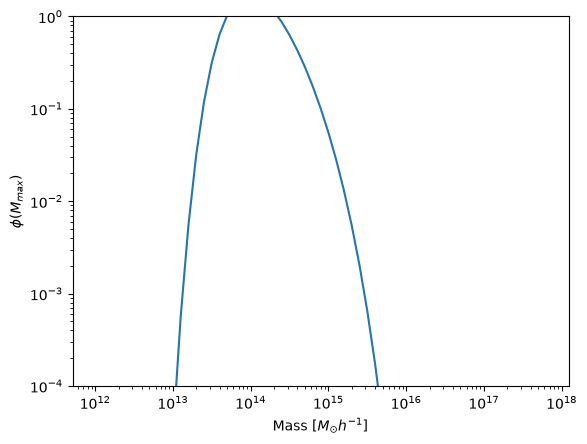

In [3]:
if __name__ == '__main__':

    # initialise mass function
    mass_function = hmf.MassFunction()

    # set cosmology using astropy
    mass_function.cosmo_model = Planck13

    # set redshift
    mass_function.z = 0.0

    # set mass range and resolution
    mass_function.dlog10m = 0.1
    mass_function.Mmin = 12
    mass_function.Mmax = 18

    phi_max = evs_hypersurface_pdf(mf = mass_function)

    plt.loglog(mass_function.m[:-1], phi_max)
    plt.ylim(10**-4,1)
    plt.xlabel('Mass $[M_{\odot}h^{-1}]$')
    plt.ylabel('$\phi(M_{max})$')

    plt.show()